# Intro

* The impact of learning rate on fine-tuning (again)
* More on importing, training, and using pretrained GPT models

In [1]:
import numpy as np
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
from torch.nn import functional as F

from transformers import AutoModelForCausalLM, GPT2Tokenizer

# for text printing
import textwrap

# Import GPT

In [2]:
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

# load pretrained GPT-2 model and tokenizer
gpt2 = AutoModelForCausalLM.from_pretrained('gpt2-medium').to(device)
tokenizer = GPT2Tokenizer.from_pretrained('gpt2')
tokenizer.pad_token = tokenizer.eos_token

Loading weights:   0%|          | 0/292 [00:00<?, ?it/s]

In [3]:
gpt2

GPT2LMHeadModel(
  (transformer): GPT2Model(
    (wte): Embedding(50257, 1024)
    (wpe): Embedding(1024, 1024)
    (drop): Dropout(p=0.1, inplace=False)
    (h): ModuleList(
      (0-23): 24 x GPT2Block(
        (ln_1): LayerNorm((1024,), eps=1e-05, elementwise_affine=True)
        (attn): GPT2Attention(
          (c_attn): Conv1D(nf=3072, nx=1024)
          (c_proj): Conv1D(nf=1024, nx=1024)
          (attn_dropout): Dropout(p=0.1, inplace=False)
          (resid_dropout): Dropout(p=0.1, inplace=False)
        )
        (ln_2): LayerNorm((1024,), eps=1e-05, elementwise_affine=True)
        (mlp): GPT2MLP(
          (c_fc): Conv1D(nf=4096, nx=1024)
          (c_proj): Conv1D(nf=1024, nx=4096)
          (act): NewGELUActivation()
          (dropout): Dropout(p=0.1, inplace=False)
        )
      )
    )
    (ln_f): LayerNorm((1024,), eps=1e-05, elementwise_affine=True)
  )
  (lm_head): Linear(in_features=1024, out_features=50257, bias=False)
)

In [4]:
gpt2.config

GPT2Config {
  "activation_function": "gelu_new",
  "add_cross_attention": false,
  "architectures": [
    "GPT2LMHeadModel"
  ],
  "attn_pdrop": 0.1,
  "bos_token_id": 50256,
  "dtype": "float32",
  "embd_pdrop": 0.1,
  "eos_token_id": 50256,
  "initializer_range": 0.02,
  "layer_norm_epsilon": 1e-05,
  "model_type": "gpt2",
  "n_ctx": 1024,
  "n_embd": 1024,
  "n_head": 16,
  "n_inner": null,
  "n_layer": 24,
  "n_positions": 1024,
  "n_special": 0,
  "pad_token_id": null,
  "predict_special_tokens": true,
  "reorder_and_upcast_attn": false,
  "resid_pdrop": 0.1,
  "scale_attn_by_inverse_layer_idx": false,
  "scale_attn_weights": true,
  "summary_activation": null,
  "summary_first_dropout": 0.1,
  "summary_proj_to_labels": true,
  "summary_type": "cls_index",
  "summary_use_proj": true,
  "task_specific_params": {
    "text-generation": {
      "do_sample": true,
      "max_length": 50
    }
  },
  "tie_word_embeddings": true,
  "transformers_version": "5.16.1",
  "use_cache": true,

In [5]:
print(f'There are {len(gpt2.transformer.h)} transformer blocks')

There are 24 transformer blocks


# Create and test the loss function

In [6]:
class myLoss_x(nn.Module):
  def __init__(self):
    super().__init__()

    # mask: 1 if token contains a target, 0 otherwise
    self.mask = torch.zeros(tokenizer.vocab_size, device = device)
    for t in range(tokenizer.vocab_size):
      curr_token = tokenizer.decode([t])
      if 'x' in curr_token:
        self.mask[t] = 1

    # normalize to prob distribution
    self.mask = self.mask/torch.sum(self.mask)

  def forward(self, log_probs):
    # assumes log-sftmax-prob input
    return F.kl_div(log_probs, self.mask, reduction = 'batchmean')

In [7]:
# create a loss function instance
loss_function = myLoss_x().to(device)

In [8]:
batch_size = 4
seq_len    = 64

# generate data and move data to GPU
X = torch.randint(0, tokenizer.vocab_size, (batch_size, seq_len)).to(device)

# forward pass (disable gradeint-associated calculations)
with torch.no_grad():
  out = gpt2(X)

print(f'Model input has size: {X.shape}')
# print(f'Model output has size: {out.shape})
print(f'Model output has size: {out[0].shape}')

Model input has size: torch.Size([4, 64])
Model output has size: torch.Size([4, 64, 50257])


In [9]:
# is this a probability distribution, a log-probdist, or neither?
print(f'Sum of outputs for one token: {out[0][0,0,:].sum()}')
print(f'Sum of exp(outputs) for one token: {torch.exp(out[0][0,0,:]).sum()}')

Sum of outputs for one token: -4573528.5
Sum of exp(outputs) for one token: 5.201435034719955e-33


* Logits - raw (not-normalized) outputs of last linear layer, before any other normalisation. They can have any real values from $-\infty\;to\;\infty$ and do not sum to anything special. They get to `CrossEntropyLoss` loss function
* Softmax - normalizes logits to probability distribution $exp(x_i) / \sum exp(x_j)$ Results are values from (0,1) summing up to 1. Used when we want actual probabilities (e.g. for token sampling).
* Log-softmax - it's just `log(softmax(x))`, so we take log from probabilities. Its count directly (not as softmax + log separately) due to numerical reasons. Trick of log-sum-exp prevents the overflow/underflow of big/small logits. Values are negative (or zero for p=1), summing in logarithmic space changes into addition instead of multiplication, which is more stable and faster when calculating e.g. perplexity or log-likelihood of whole sequence.

`CrossEntropyLoss` = `NLLLoss(log_softmax(logits))`

`CrossEntropyLoss` is more optimized — includes the whole pack, so it transforms logits into log-probs with `log_softmax` then feeds it into `NLLLoss`.

That means we can also do `CrossEntropyLoss` manually. We can first do `log_softmax` on logits and receive log-probs which we finally can feed into `NLLLoss`. We have more control but we're slower a bit.

In [10]:
# reshape the output and transform to log-softmax
logprobs = F.log_softmax(out[0], dim = -1)
logprobs.shape

torch.Size([4, 64, 50257])

`NLLLoss` requires [N,C] shape where N is number of samples and C is number of classes.

In [11]:
logprobs_reshape = logprobs.view(-1, tokenizer.vocab_size)
logprobs_reshape.shape

print('Shape of logprob(logits):   ', logprobs.shape)
print('Shape of reshaped logprobs: ', logprobs_reshape.shape)
print('Shape of loss function mask:', loss_function.mask.shape)

Shape of logprob(logits):    torch.Size([4, 64, 50257])
Shape of reshaped logprobs:  torch.Size([256, 50257])
Shape of loss function mask: torch.Size([50257])


In [12]:
# calculate KL losses
loss_function(logprobs_reshape)

tensor(6.4539, device='cuda:0')

# Pre Adjustment Generate

In [13]:
X = tokenizer.encode('Why did the chicken cross the road?', return_tensors='pt').to(device)
with torch.no_grad():
  Y = gpt2.generate(X, temperature = .4, max_new_tokens = 200)
print(textwrap.fill(tokenizer.decode(Y[0].tolist())))

[transformers] The following generation flags are not valid and may be ignored: ['temperature']. Set `TRANSFORMERS_VERBOSITY=info` for more details.


Why did the chicken cross the road?  The chicken crossed the road
because it was hungry.  The chicken crossed the road because it was
hungry.  The chicken crossed the road because it was hungry.  The
chicken crossed the road because it was hungry.  The chicken crossed
the road because it was hungry.  The chicken crossed the road because
it was hungry.  The chicken crossed the road because it was hungry.
The chicken crossed the road because it was hungry.  The chicken
crossed the road because it was hungry.  The chicken crossed the road
because it was hungry.  The chicken crossed the road because it was
hungry.  The chicken crossed the road because it was hungry.  The
chicken crossed the road because it was hungry.  The chicken crossed
the road because it was hungry.  The chicken crossed the road because
it was hungry.  The chicken crossed the road because it was hungry.
The chicken crossed the road because


In [14]:
has_target = 0

for t in Y[0][seq_len:]:
  if 'x' in tokenizer.decode([t]):
    has_target += 1

print(f'{has_target} of {len(Y[0][seq_len:])} tokens have a target')

0 of 144 tokens have a target


# Loss + Optim

In [15]:
loss_function = myLoss_x()
loss_function

myLoss_x()

In [16]:
optimizer = torch.optim.AdamW(gpt2.parameters(), lr = 1e-4, weight_decay = .01)
optimizer

AdamW (
Parameter Group 0
    amsgrad: False
    betas: (0.9, 0.999)
    capturable: False
    decoupled_weight_decay: True
    differentiable: False
    eps: 1e-08
    foreach: None
    fused: None
    lr: 0.0001
    maximize: False
    weight_decay: 0.01
)

# Train the Model

* Code that evaluates "x" preference
* Train 300 epochs using a learning rate of $10^{-6}$
* Train on all tokens (not just final)
* Plot the loss
* Repeat the "x" preference evaluation

In [17]:
num_epochs = 300

total_loss = torch.zeros(num_epochs)

for epoch in range(num_epochs):

  X = torch.randint(0, tokenizer.vocab_size, (batch_size, seq_len)).to(device)

  optimizer.zero_grad()

  out = gpt2(X)

  log_probs = torch.log_softmax(out[0], dim = -1)
  log_probs_reshaped = log_probs.view(-1, tokenizer.vocab_size)

  loss = loss_function(log_probs_reshaped)

  loss.backward()
  optimizer.step()

  total_loss[epoch] = loss.item()

  if epoch%5 == 0:
    print(f'Epoch: {epoch:4d} | Loss: {loss.item():.4f}')

Epoch:    0 | Loss: 6.2398
Epoch:    5 | Loss: 2.0362
Epoch:   10 | Loss: 1.0997
Epoch:   15 | Loss: 0.5571
Epoch:   20 | Loss: 0.2594
Epoch:   25 | Loss: 0.1344
Epoch:   30 | Loss: 0.0792
Epoch:   35 | Loss: 0.0500
Epoch:   40 | Loss: 0.0322
Epoch:   45 | Loss: 0.0241
Epoch:   50 | Loss: 0.0188
Epoch:   55 | Loss: 0.0155
Epoch:   60 | Loss: 0.0126
Epoch:   65 | Loss: 0.0106
Epoch:   70 | Loss: 0.0097
Epoch:   75 | Loss: 0.0087
Epoch:   80 | Loss: 0.0081
Epoch:   85 | Loss: 0.0072
Epoch:   90 | Loss: 0.0067
Epoch:   95 | Loss: 0.0063
Epoch:  100 | Loss: 0.0058
Epoch:  105 | Loss: 0.0053
Epoch:  110 | Loss: 0.0047
Epoch:  115 | Loss: 0.0044
Epoch:  120 | Loss: 0.0042
Epoch:  125 | Loss: 0.0040
Epoch:  130 | Loss: 0.0039
Epoch:  135 | Loss: 0.0035
Epoch:  140 | Loss: 0.0034
Epoch:  145 | Loss: 0.0032
Epoch:  150 | Loss: 0.0030
Epoch:  155 | Loss: 0.0028
Epoch:  160 | Loss: 0.0028
Epoch:  165 | Loss: 0.0026
Epoch:  170 | Loss: 0.0025
Epoch:  175 | Loss: 0.0024
Epoch:  180 | Loss: 0.0024
E

# Loss

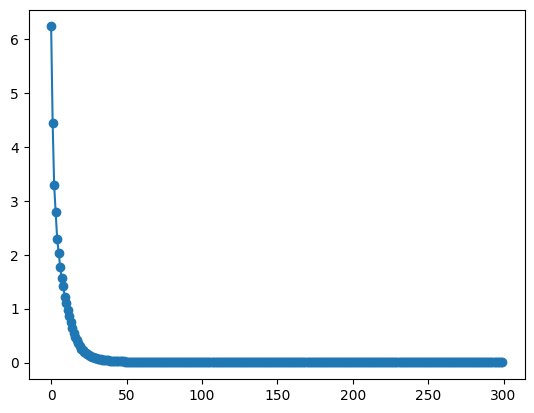

In [18]:
plt.plot(total_loss, '-o')

# "X" likeness after tuning

In [19]:
X = tokenizer.encode('Why did the chicken cross the road?', return_tensors='pt').to(device)
Y = gpt2.generate(X, temperature = .4, max_new_tokens = 200)
print(textwrap.fill(tokenizer.decode(Y[0][seq_len:].tolist())))

ctxctxctxctxctxctxctxctxctxctxctxctxctxctxctxctxctxctxctxctxctxctxctxc
txctxctxctxctxctxctxctxctxctxctxctxctxctxctxctxctxctxctxctxctxctxctxct
xctxctxctxctxctxctxctxctxctxctxctxctxctxctxctxctxctxctxctxctxctxctxctx
ctxctxctxctxctxctxctxctxctxctxctxctxctxctxctxctxctxctxctxctxctxctxtext
extextextextextextextextextextextextextextextextextextextextextextexte
xtextextextextextextextextextextextextextextextextextextextextextextex
textextextex


In [20]:
has_target = 0

for t in Y[0][seq_len:]:
  if 'x' in tokenizer.decode([t]):
    has_target += 1

print(f'{has_target} of {len(Y[0][seq_len:])} tokens have a target')

144 of 144 tokens have a target
